new: 2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg183_pion.h5: 183 cfgs, pz = 6, basis ['rho4p5z2p25 G5', 'rho4p5z2p25 G5G4', 'rho4p5z2p25 G3G5', 'rho1p5 G5', 'rho1p5 G5G4', 'rho1p5 G3G5'], t0 = 1, t_ref = 3
old: twopt_source_averaged.h5: 183 cfgs (same), pz = 6

fb, pz = 6, continuum dispersion E = 1.1865;  old has 1024 sources per cfg, new 3072
  t              old m_eff              new m_eff  err new/old
  0         1.4561(0.0002)         2.2936(0.0002)         1.19
  1         1.2589(0.0002)         1.2188(0.0002)         1.19
  2         1.2237(0.0002)         1.1772(0.0003)         1.37
  3         1.2009(0.0002)         1.1568(0.0005)         2.36
  4         1.1847(0.0003)         1.1429(0.0012)         3.78
  5         1.1730(0.0004)         1.1368(0.0026)         6.08
  6         1.1614(0.0009)         1.1136(0.0057)         6.53
  7         1.1539(0.0020)         1.1183(0.0159)         7.79
  8         1.1452(0.0049)      

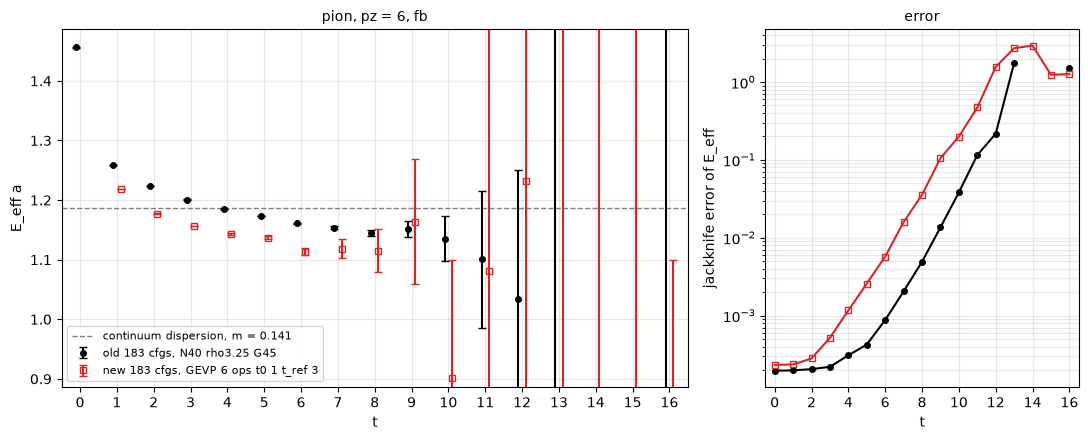

In [22]:
#Effective mass at one pz, old against new, pion at forward q = 0. Only local 2pt files are read; nothing is saved, the plot is only shown.
#  old: the 799-cfg 2pt, N40 rho3.25 frac0.6 Wuppertal smearing, one operator, 8 t_src x 4 x 4 x 8 = 1024 sources per cfg:
#       G45: 2PT_simple/twopt_source_averaged.h5, already averaged over the sources, all 96 time slices counted from the source,
#            so forward C(t_src + t) = C[t] and backward C(t_src - t) = C[96 - t]
#       G5:  799cfgs/2pt_N40_rho3.25_G5_..._ncfg799.h5, per source, tsep 0..17, averaged over the sources here
#  new: the packed final Delta 2pt with the most cfgs (24 t_src x 128 sources per cfg, tsep 0..19, 6 operators: 2 smearings x G5, G5G4, G3G5).
#       The GEVP is solved here as in section 1 of the offforward notebook: per half (forward, backward), C(t) = c_sign x hermitian part of the
#       t_src-averaged matrix of the basis; C(t) v = lambda C(t0) v on its cfg mean (Cholesky of C(t0)); v0 = ground-state vector at t_ref,
#       normalized to v0^dag C(t0) v0 = 1. The reconstructed 2pt of every cfg is Re v0^dag C_cfg(t) v0. A basis of one operator gives its diagonal 2pt.
#m_eff(t) = ln C(t)/C(t+1) on the delete-one jackknife replicates over cfgs, for forward, backward, or fb = their mean.
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt

here = "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta"
old_file = {"G45": "/Users/mcp3270/Desktop/GLUON_analysis_simple/GLUON_ANALYSIS_MANUAL/2PT_simple/twopt_source_averaged.h5",
            "G5": "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/799cfgs/2pt_N40_rho3.25_G5_ez_momfrac0p6_fb_tsep18_ncfg799.h5"}

hadron = "pion"                                 # the old 2pt exists for the pion only
direction = "fb"                                # "forward", "backward" or "fb"
pz = 6                                          # momentum (0, 0, pz)
smear_use, gamma_use, t0, t_ref = [0, 1], [0, 1, 2], 1, 3     # new: GEVP basis; smear 0 = [4.5, 2.25, 0.8], 1 = [1.5, 1.5, 0]; gamma 0 = G5, 1 = G5G4, 2 = G3G5
old_gamma = "G45"                               # old: "G5" or "G45"
old_cfgs = "same"                                # "all": the 799 cfgs; "same": only the cfgs of the new file, so that both have the same cfgs
t_plot_max = 16                                 # last t of the points (m_eff exists up to 18; old G5 only up to 16)
m_had = 0.141                                   # for the continuum dispersion line and the y range
Ls, Lt = 32, 96
c_sign = {"pion": -1, "proton": +1}[hadron]     # new data: the pion comes out negative (the fermion-loop sign is not in the code)
old_sign = {"G5": +1, "G45": -1}[old_gamma]     # old data: the G5 file is positive, the G45 file negative
assert hadron == "pion", "there is no old 2pt of the proton"


def jk(data):
    #mean and jackknife error over axis 0 of delete-one replicates
    n = data.shape[0]
    mean = np.mean(data, axis=0)
    return mean, np.sqrt((n - 1.0) / n * np.sum((data - mean) ** 2, axis=0))


def meff(C):
    #C (cfg, tsep) -> mean and jackknife error of ln C(t)/C(t+1), t = 0 .. tsep_max - 2
    n = C.shape[0]
    C_jk = (C.sum(axis=0)[None] - C) / (n - 1)
    with np.errstate(invalid="ignore", divide="ignore"):
        return jk(np.log(C_jk[:, :-1] / C_jk[:, 1:]))


def ncfg_of(name):
    return int(name.split("_ncfg")[1].split("_")[0].split(".")[0])


def text(values):
    return [v.decode() if isinstance(v, bytes) else str(v) for v in values]


halves = ("forward", "backward")

#======== new: the packed 2pt with the most cfgs, the 6 x 6 matrix at this pz, GEVP per half ========
found = glob.glob(f"{here}/2pt_*_GEVP_forward_q0_0_0_C3input_*_ncfg*_{hadron}.h5")
assert found, f"no packed forward {hadron} 2pt in {here}"
new_file = max(found, key=ncfg_of)
with h5py.File(new_file, "r") as f:
    cfg_new = f["cfg_list"][:]
    ip = f["pf_list"][:].tolist().index([0, 0, pz])
    smear_names, gamma_list = text(f["smear_names"][:]), text(f.attrs["gamma_list"])
    pt2 = {d: f[f"pt2_{d}"][:, :, :, :, :, :, ip, :] for d in halves}      # (cfg, smear_snk, smear_src, g_snk, g_src, t_src, tsep)
n_new, n_op = len(cfg_new), len(smear_use) * len(gamma_use)
op_labels = [f"{smear_names[s]} {gamma_list[g]}" for s in smear_use for g in gamma_use]
C_new = {}
for d in halves:
    #---- the operator matrix of the basis, per cfg, mean over t_src
    x = pt2[d][:, smear_use][:, :, smear_use][:, :, :, gamma_use][:, :, :, :, gamma_use]
    matrix = x.transpose(0, 1, 3, 2, 4, 5, 6).reshape(n_new, n_op, n_op, x.shape[5], x.shape[6])   # (cfg, op_snk, op_src, t_src, tsep), op = (smear, gamma)
    C_cfg = c_sign * matrix.mean(axis=3)                                                           # mean over t_src: (cfg, op, op, tsep)
    C_cfg = 0.5 * (C_cfg + np.conj(np.swapaxes(C_cfg, 1, 2)))                                      # hermitian part
    C_mean = C_cfg.mean(axis=0)                                                                    # (op, op, tsep)
    #---- GEVP C(t_ref) v = lambda C(t0) v on the cfg mean: ground-state vector v0
    L_inv = np.linalg.inv(np.linalg.cholesky(C_mean[:, :, t0]))
    w, u = np.linalg.eigh(L_inv @ C_mean[:, :, t_ref] @ L_inv.conj().T)
    v0 = (L_inv.conj().T @ u)[:, np.argmax(w)]                                                     # ground state at t_ref, v0^dag C(t0) v0 = 1
    #---- reconstructed 2pt of every cfg
    C_new[d] = np.einsum("a,cabt,b->ct", v0.conj(), C_cfg, v0).real                               # (cfg, tsep)
C_new["fb"] = 0.5 * (C_new["forward"] + C_new["backward"])
new_label = (f"new {n_new} cfgs, " + (f"GEVP {n_op} ops t0 {t0} t_ref {t_ref}" if n_op > 1 else op_labels[0]))
print(f"new: {os.path.basename(new_file)}: {n_new} cfgs, pz = {pz}, basis {op_labels}, t0 = {t0}, t_ref = {t_ref}")

#======== old: one operator, mean over the 1024 sources per cfg ========
old_path = old_file[old_gamma]
with h5py.File(old_path, "r") as f:
    cfg_old = f["cfg_list"][:]
    if old_cfgs == "same":
        rows = [list(cfg_old).index(c) for c in cfg_new]
        assert len(rows) == n_new, "not every new cfg is among the old cfgs"
    else:
        rows = list(range(len(cfg_old)))
    cfg_old = cfg_old[rows]
    C_old = {}
    if old_gamma == "G45":                                     # source-averaged: (cfg, momentum, t), t = 0..95 counted from the source
        im = f["momentum_list"][:].tolist().index([0, 0, pz])
        C = f["correlator_cfg"][:, im, :][rows].real            # (cfg, 96)
        tsep = np.arange(20)                                    # tsep 0..19, as the new data
        C_old["forward"], C_old["backward"] = old_sign * C[:, tsep], old_sign * C[:, (Lt - tsep) % Lt]
    else:                                                      # per source: one cfg at a time (3.3 GB file), (t_src, x, y, z, pf, tsep) -> mean over the sources at this pz
        ip_old = f["pf_list"][:].tolist().index([0, 0, pz])
        for d in halves:
            C_old[d] = old_sign * np.stack([f[f"pt2_{d}"][ic][..., ip_old, :].mean(axis=(0, 1, 2, 3)) for ic in rows]).real
C_old["fb"] = 0.5 * (C_old["forward"] + C_old["backward"])
n_old = len(cfg_old)
old_label = f"old {n_old} cfgs, N40 rho3.25 {old_gamma}"
print(f"old: {os.path.basename(old_path)}: {n_old} cfgs ({old_cfgs}), pz = {pz}")

#======== effective masses and the comparison ========
old_mean, old_err = meff(C_old[direction])
new_mean, new_err = meff(C_new[direction])
E_disp = np.sqrt(m_had ** 2 + (2 * np.pi * pz / Ls) ** 2)
print(f"\n{direction}, pz = {pz}, continuum dispersion E = {E_disp:.4f};  old has {8 * 128} sources per cfg, new {24 * 128}")
print(f"{'t':>3} {'old m_eff':>22} {'new m_eff':>22} {'err new/old':>12}")
for t in range(0, t_plot_max + 1):
    o = f"{old_mean[t]:.4f}({old_err[t]:.4f})" if t < len(old_mean) else "-"
    n = f"{new_mean[t]:.4f}({new_err[t]:.4f})" if t < len(new_mean) else "-"
    r = f"{new_err[t] / old_err[t]:.2f}" if t < min(len(old_mean), len(new_mean)) else "-"
    print(f"{t:>3} {o:>22} {n:>22} {r:>12}")
if old_cfgs == "all":
    print(f"(the cfg numbers alone give err new/old = sqrt({n_old}/{n_new}) = {np.sqrt(n_old / n_new):.2f}; set old_cfgs = 'same' for the same cfgs)")

fig, (ax_m, ax_e) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [2, 1]})
t_old = np.arange(min(t_plot_max + 1, len(old_mean)))
t_new = np.arange(min(t_plot_max + 1, len(new_mean)))
ax_m.axhline(E_disp, color="gray", lw=1, ls="--", label=f"continuum dispersion, m = {m_had}")
ax_m.errorbar(t_old - 0.1, old_mean[t_old], old_err[t_old], fmt="o", ms=4, color="k", capsize=3, label=old_label)
ax_m.errorbar(t_new + 0.1, new_mean[t_new], new_err[t_new], fmt="s", ms=4, color="C3", mfc="none", capsize=3, label=new_label)
ax_m.set_ylim(E_disp - 0.3, E_disp + 0.3)
ax_m.set_xlim(-0.5, t_plot_max + 0.5)
ax_m.set_xticks(np.arange(t_plot_max + 1))
ax_m.set_xlabel("t")
ax_m.set_ylabel("E_eff a")
ax_m.set_title(f"{hadron}, pz = {pz}, {direction}", fontsize=10)
ax_m.legend(fontsize=8)
ax_m.grid(alpha=0.3)
ax_e.plot(t_old, old_err[t_old], "o-", ms=4, color="k", label=old_label)
ax_e.plot(t_new, new_err[t_new], "s-", ms=4, color="C3", mfc="none", label=new_label)
ax_e.set_yscale("log")
ax_e.set_xlim(-0.5, t_plot_max + 0.5)
ax_e.set_xticks(np.arange(0, t_plot_max + 1, 2))
ax_e.set_xlabel("t")
ax_e.set_ylabel("jackknife error of E_eff")
ax_e.set_title("error", fontsize=10)
ax_e.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()